# Did the Process Redesign Work? — Project Delivery KPI Analysis

**Context:** A four-person project coordination team brought in a redesigned way of working in January 2025:
standard plan templates, fewer hand-offs and a weekly status rhythm.

**Question:** Did on-time delivery actually improve, by how much, is the change real or noise, and where is it still weak?

**Methods:** KPI definitions, before/after comparison, chi-square & Mann-Whitney tests, a p-chart (statistical process control),
and breakdowns by category and coordinator.

> Data is **synthetic** (`src/generate_data.py`), modelled on a real process-optimisation programme I led.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
Path("images").mkdir(exist_ok=True)

df = pd.read_csv("data/task_log.csv", parse_dates=["start_date", "due_date", "completed_date"])
REDESIGN = pd.Timestamp("2025-01-06")
df["period"] = np.where(df.start_date >= REDESIGN, "After", "Before")
df["on_time"] = df.completed_date <= df.due_date
df["days_late"] = (df.completed_date - df.due_date).dt.days.clip(lower=0)
df["month"] = df.start_date.dt.to_period("M")
print(df.shape); df.head()

(1450, 14)


,task_id,start_date,category,coordinator,planned_days,actual_days,due_date,completed_date,handoffs,required_rework,period,on_time,days_late,month
0,T01031,2024-05-06,Field deployment,Coordinator C,14,30,2024-05-20,2024-06-05,6,False,Before,False,16,2024-05
1,T01123,2024-05-06,Stakeholder report,Coordinator D,2,5,2024-05-08,2024-05-11,5,False,Before,False,3,2024-05
2,T00361,2024-05-07,Field deployment,Coordinator C,15,29,2024-05-22,2024-06-05,4,False,Before,False,14,2024-05
3,T01187,2024-05-07,Stakeholder report,Coordinator A,5,11,2024-05-12,2024-05-18,4,False,Before,False,6,2024-05
4,T00138,2024-05-07,Training rollout,Coordinator A,9,9,2024-05-16,2024-05-16,4,False,Before,True,0,2024-05


## 1. KPI definitions
| KPI | Definition |
|---|---|
| On-time rate | share of tasks completed on or before the due date |
| Avg days late | mean days past due, late tasks only |
| Schedule variance | (actual − planned) / planned |
| Rework rate | share of tasks that had to be reopened |
| Hand-offs per task | number of owner changes during the task |

In [2]:
df["schedule_variance"] = (df.actual_days - df.planned_days) / df.planned_days
kpi = (df.groupby("period")
       .agg(tasks=("task_id", "count"),
            on_time_rate=("on_time", "mean"),
            avg_days_late=("days_late", lambda s: s[s > 0].mean()),
            median_schedule_var=("schedule_variance", "median"),
            rework_rate=("required_rework", "mean"),
            handoffs_per_task=("handoffs", "mean"))
       .loc[["Before", "After"]])
kpi.T.style.format("{:.2f}")

period,Before,After
tasks,640.00,810.00
on_time_rate,0.48,0.83
avg_days_late,7.47,4.26
median_schedule_var,0.30,0.00
rework_rate,0.18,0.09
handoffs_per_task,4.17,2.52


In [3]:
before, after = kpi.loc["Before", "on_time_rate"], kpi.loc["After", "on_time_rate"]
print(f"On-time rate: {before:.1%} -> {after:.1%}")
print(f"Absolute change: {after - before:+.1%} pts | relative lift: {(after / before - 1):+.0%}")

On-time rate: 48.0% -> 82.7%
Absolute change: +34.7% pts | relative lift: +72%


## 2. Is the change statistically real?

In [4]:
table = pd.crosstab(df.period, df.on_time)
chi2, p, _, _ = stats.chi2_contingency(table)
print(table, f"\nChi-square = {chi2:.1f}, p = {p:.2e}")

late_b = df.query("period == 'Before' and days_late > 0").days_late
late_a = df.query("period == 'After' and days_late > 0").days_late
u = stats.mannwhitneyu(late_b, late_a, alternative="greater")
print(f"\nDays late (late tasks only): median {late_b.median():.0f} -> {late_a.median():.0f}, "
      f"Mann-Whitney one-sided p = {u.pvalue:.2e}")

# 95% CI for the difference in proportions
nb, na = table.loc["Before"].sum(), table.loc["After"].sum()
se = np.sqrt(before * (1 - before) / nb + after * (1 - after) / na)
print(f"Difference in on-time rate: {after - before:.1%} (95% CI {after - before - 1.96*se:.1%} to {after - before + 1.96*se:.1%})")

on_time  False  True 
period               
After      140    670
Before     333    307 
Chi-square = 194.8, p = 2.83e-44

Days late (late tasks only): median 6 -> 4, Mann-Whitney one-sided p = 6.16e-14
Difference in on-time rate: 34.7% (95% CI 30.1% to 39.4%)


## 3. Process control view (p-chart)
A before/after average can hide a one-off good month. A p-chart shows whether the process *shifted and stayed shifted*.
Control limits are calculated from the **before** period, so points above the upper limit after January are a real signal.

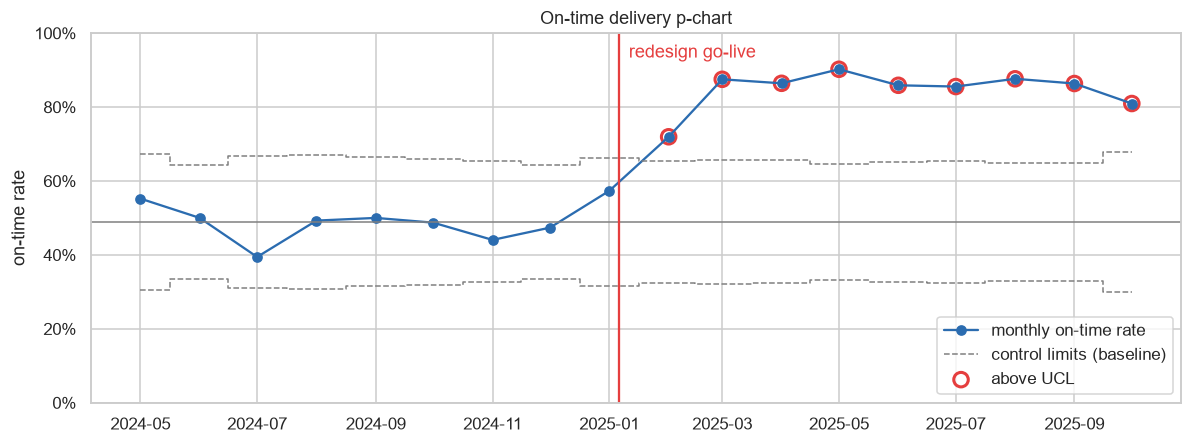

Baseline p = 48.9%; months above UCL after go-live: 9 of 9


In [5]:
m = df.groupby("month").agg(n=("on_time", "size"), rate=("on_time", "mean")).reset_index()
m["month_ts"] = m.month.dt.to_timestamp()
base = m[m.month_ts < REDESIGN]
p_bar = (base.rate * base.n).sum() / base.n.sum()
m["ucl"] = p_bar + 3 * np.sqrt(p_bar * (1 - p_bar) / m.n)
m["lcl"] = (p_bar - 3 * np.sqrt(p_bar * (1 - p_bar) / m.n)).clip(lower=0)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(m.month_ts, m.rate, marker="o", color="#2b6cb0", label="monthly on-time rate")
ax.step(m.month_ts, m.ucl, where="mid", color="grey", ls="--", lw=1, label="control limits (baseline)")
ax.step(m.month_ts, m.lcl, where="mid", color="grey", ls="--", lw=1)
ax.axhline(p_bar, color="grey", lw=1)
ax.axvline(REDESIGN, color="#e53e3e", lw=1.5); ax.text(REDESIGN, 0.97, "  redesign go-live", color="#e53e3e", va="top")
signal = m[(m.rate > m.ucl)]
ax.scatter(signal.month_ts, signal.rate, s=90, facecolors="none", edgecolors="#e53e3e", lw=2, label="above UCL")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylim(0, 1)
ax.set(title="On-time delivery p-chart", ylabel="on-time rate"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("images/p_chart.png", bbox_inches="tight"); plt.show()
print(f"Baseline p = {p_bar:.1%}; months above UCL after go-live: {len(signal)} of {(m.month_ts >= REDESIGN).sum()}")

## 4. Where did it improve, and where is it still weak?

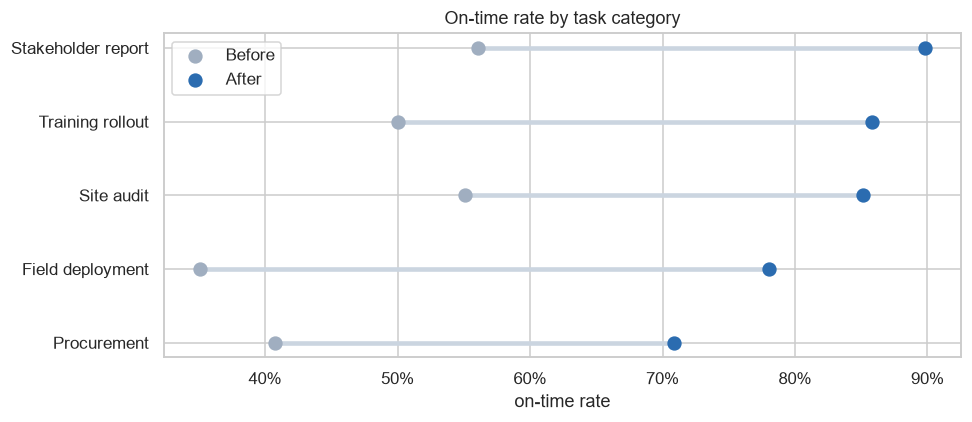

period,Before,After,change_pts
category,,,
Procurement,41%,71%,+30
Field deployment,35%,78%,+43
Site audit,55%,85%,+30
Training rollout,50%,86%,+36
Stakeholder report,56%,90%,+34


In [6]:
by_cat = (df.pivot_table(index="category", columns="period", values="on_time", aggfunc="mean")
          [["Before", "After"]].assign(change_pts=lambda d: (d.After - d.Before) * 100)
          .sort_values("After"))

fig, ax = plt.subplots(figsize=(9, 4))
for i, (cat, r) in enumerate(by_cat.iterrows()):
    ax.plot([r.Before, r.After], [i, i], color="#cbd5e0", lw=3, zorder=1)
ax.scatter(by_cat.Before, range(len(by_cat)), color="#a0aec0", s=70, label="Before", zorder=2)
ax.scatter(by_cat.After, range(len(by_cat)), color="#2b6cb0", s=70, label="After", zorder=2)
ax.set_yticks(range(len(by_cat)), by_cat.index)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set(title="On-time rate by task category", xlabel="on-time rate"); ax.legend()
plt.tight_layout(); plt.savefig("images/by_category.png", bbox_inches="tight"); plt.show()
by_cat.style.format({"Before": "{:.0%}", "After": "{:.0%}", "change_pts": "{:+.0f}"})

In [7]:
by_coord = df.pivot_table(index="coordinator", columns="period", values="on_time", aggfunc="mean")[["Before", "After"]]
by_coord["tasks_after"] = df[df.period == "After"].groupby("coordinator").size()
by_coord.style.format({"Before": "{:.0%}", "After": "{:.0%}"})

period,Before,After,tasks_after
coordinator,,,
Coordinator A,49%,81%,187
Coordinator B,50%,87%,187
Coordinator C,45%,77%,226
Coordinator D,48%,87%,210


## 5. What changed in how work flows?

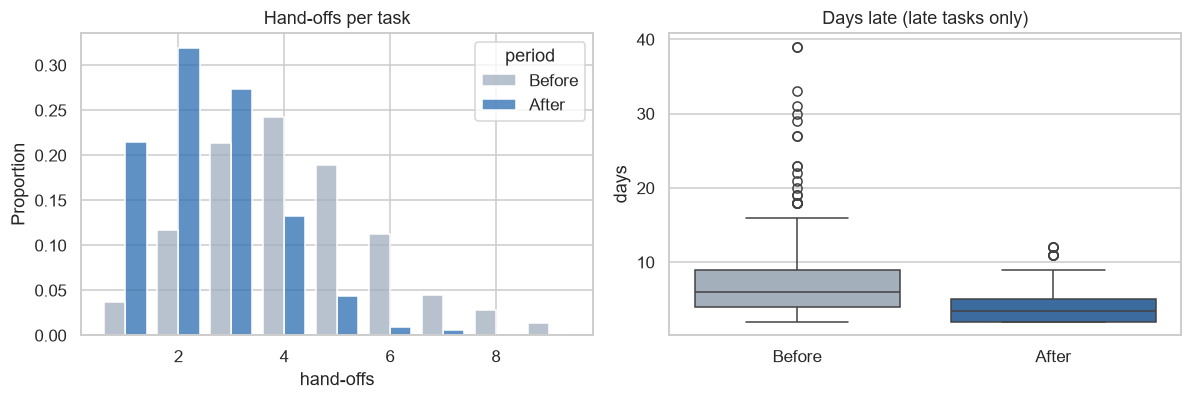

Spearman correlation, hand-offs vs on-time: r = -0.21 (p = 1.0e-15)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=df, x="handoffs", hue="period", hue_order=["Before", "After"], discrete=True,
             stat="proportion", common_norm=False, multiple="dodge", shrink=0.8, ax=axes[0],
             palette=["#a0aec0", "#2b6cb0"])
axes[0].set(title="Hand-offs per task", xlabel="hand-offs")
sns.boxplot(data=df[df.days_late > 0], x="period", y="days_late", order=["Before", "After"], ax=axes[1],
            palette=["#a0aec0", "#2b6cb0"], hue="period", legend=False)
axes[1].set(title="Days late (late tasks only)", xlabel="", ylabel="days")
plt.tight_layout(); plt.savefig("images/flow_changes.png", bbox_inches="tight"); plt.show()

r, p = stats.spearmanr(df.handoffs, df.on_time)
print(f"Spearman correlation, hand-offs vs on-time: r = {r:.2f} (p = {p:.1e})")

## Findings
- On-time delivery **rose sharply after the redesign**, and the chi-square test and confidence interval show the change is far beyond random variation.
- The p-chart shows the process **moved and stayed moved**: after a short adoption ramp, every month sits above the old upper control limit.
- Tasks that do slip are **late by fewer days**, and **hand-offs per task fell by about 40%** (4.2 → 2.5). Rework fell from 18% to 9% of tasks. Fewer hand-offs go with better on-time delivery.
- **Still weakest:** Procurement and Field deployment. Supplier lead times and logistics sit partly outside the team's control, so these are the next places to focus.

*Limitations:* this is an observational before/after comparison, not a controlled experiment. Seasonality and team changes could contribute.